<a href="https://www.kaggle.com/code/aamir28/nlp-assignment-3-word2vec?scriptVersionId=365186568" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# NLP Assignment 3: Word2Vec, Pseudocode + Python on the Bollywood Movies Dataset

**Topics covered**

1. Preparing the data for Word2Vec (sentences as lists of tokens)
2. What Word2Vec is: CBOW vs Skip-gram
3. Training Word2Vec (CBOW and Skip-gram)
4. Vocabulary and word vectors
5. Word similarity (`most_similar`, `similarity`)
6. CBOW vs Skip-gram comparison
7. Analogies and odd-one-out
8. Visualising the word vectors (PCA)
9. Document vectors (average Word2Vec) and finding similar movies
10. Effect of hyperparameters (window, vector size)
11. Observations and summary

Each section has: **what and why**, **pseudocode**, **Python code**, and a short **observation** space for your assignment.

> Dataset: `bollywood_movies_nlp_dataset.csv` with columns `movie`, `description`, `genre`.

> **Important:** this dataset is tiny (168 short descriptions, only a couple of thousand words). Word2Vec normally needs millions of words, so the similarities you get here will be rough and sometimes odd. That is itself a good observation for the assignment. Section 11 shows how to compare with pretrained vectors.

In [1]:
# Run once (Kaggle/Colab usually already have most of these)
!pip install -q gensim nltk emoji beautifulsoup4 scikit-learn matplotlib

In [2]:
import re, string, os, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

warnings.filterwarnings("ignore")
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

pd.set_option("display.max_colwidth", 120)
SEED = 42

## 0. Load the data

**Pseudocode**
```
FILE = "bollywood_movies_nlp_dataset.csv"
SEARCH for FILE in: current folder, the Kaggle input folder
df = READ csv from the first location where FILE exists
```

In [3]:
candidates = [
    "bollywood_movies_nlp_dataset.csv",
    "/kaggle/input/datasets/aamir28/nlp-text-preprocessing-dataset/bollywood_movies_nlp_dataset.csv",
    "/kaggle/input/bollywood-movies-dataset-for-nlp/bollywood_movies_nlp_dataset.csv",
]
path = next((p for p in candidates if os.path.exists(p)), None)
if path is None and os.path.exists("/kaggle/input"):
    for root, _, files in os.walk("/kaggle/input"):
        if "bollywood_movies_nlp_dataset.csv" in files:
            path = os.path.join(root, "bollywood_movies_nlp_dataset.csv")
            break
assert path, "Upload bollywood_movies_nlp_dataset.csv next to this notebook"

df = pd.read_csv(path)
print(path, df.shape)
df.head()

/kaggle/input/datasets/aamir28/nlp-text-preprocessing-dataset/bollywood_movies_nlp_dataset.csv (168, 3)


,movie,description,genre
0,Sholay,Two petty criminals are hired by a retired police officer to capture a ruthless dacoit terrorising a village. Friend...,"Action, Adventure"
1,Mughal-E-Azam,"Prince Salim falls in love with the court dancer Anarkali, defying his father Emperor Akbar. The epic tells a grand ...","Drama, Romance, History"
2,Mother India,A poor village woman struggles to raise her sons and uphold her principles amid hardship and debt. Her sacrifices ma...,Drama
3,Pyaasa,A disillusioned poet finds that the world values him more after his supposed death than during his life. A bitter lo...,"Drama, Musical"
4,Guide,"A tour guide helps an unhappy dancer become a star, but love and ego lead him down an unexpected spiritual path.","Drama, Romance"


## 1. Preparing the data for Word2Vec

**Why:** Word2Vec learns from **context**: which words appear near which other words. So it does not want one big bag of words. It wants a list of **sentences**, and each sentence is a **list of tokens**:

```
[ ["two", "petty", "criminal", "hire", "retire", "police", "officer", ...],
  ["friendship", "revenge", "iconic", "dialogue", "define", ...],
  ... ]
```

We **split every description into sentences first** so that a context window never crosses a sentence boundary, then clean each sentence.

For a corpus this small we also **remove stop words** (otherwise *the, a, of* dominate every context). On a large corpus many people keep them.

**Pseudocode**
```
sentences = EMPTY list
FOR each description IN dataset:
    FOR each sentence IN split_into_sentences(description):
        tokens = preprocess(sentence)       # lowercase, remove punctuation, stop words, lemmatize
        IF tokens has at least 2 words:     # a 1-word sentence has no context
            ADD tokens to sentences
```

In [4]:
from bs4 import BeautifulSoup
import emoji
from nltk.corpus import stopwords, wordnet
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

stop_words = set(stopwords.words("english")) - {"not", "no", "nor"}
lem = WordNetLemmatizer()

def get_wordnet_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

def preprocess(text):
    text = BeautifulSoup(text, "html.parser").get_text()          # remove HTML
    text = re.sub(r"(https?://|www\.)\S+", "", text)               # remove URLs
    text = text.lower()
    text = emoji.replace_emoji(text, replace="")                  # remove emojis
    text = re.sub(r"'s\b", "", text)                              # srk's -> srk
    text = re.sub(r"[-/\u2013\u2014]", " ", text)                  # curry-western -> curry western
    text = text.translate(str.maketrans("", "", string.punctuation))
    tokens = [t for t in word_tokenize(text) if t not in stop_words]
    return [lem.lemmatize(w, get_wordnet_pos(t)) for w, t in pos_tag(tokens)]

sentences = []
for desc in df["description"]:
    for sent in sent_tokenize(desc):
        tokens = preprocess(sent)
        if len(tokens) >= 2:
            sentences.append(tokens)

all_tokens = [t for s in sentences for t in s]
print("Number of sentences :", len(sentences))
print("Total tokens        :", len(all_tokens))
print("Unique tokens       :", len(set(all_tokens)))
print("Example sentence    :", sentences[0])

Number of sentences : 172
Total tokens        : 1785
Unique tokens       : 947
Example sentence    : ['two', 'petty', 'criminal', 'hire', 'retired', 'police', 'officer', 'capture', 'ruthless', 'dacoit', 'terrorising', 'village']


## 2. What is Word2Vec? CBOW vs Skip-gram

**Idea:** *"You shall know a word by the company it keeps."* Words that appear in similar contexts get similar vectors. Word2Vec trains a very small neural network (one hidden layer, no activation) whose hidden weights become the **word vectors** (embeddings).

| | **CBOW** (Continuous Bag of Words) | **Skip-gram** |
|---|---|---|
| Task | Predict the **centre word** from its surrounding words | Predict the **surrounding words** from the centre word |
| Example (window=2) | `[young, man, ___, love, woman]` gives `fall` | `fall` gives `young, man, love, woman` |
| Speed | Faster | Slower |
| Works best on | Frequent words, big data | Rare words, small data |
| gensim | `sg=0` | `sg=1` |

**Pseudocode (training)**
```
INITIALISE a random vector (size D) for every word in the vocabulary
FOR epoch = 1 TO n_epochs:
    FOR each sentence IN sentences:
        FOR each position i IN sentence:
            centre  = sentence[i]
            context = words within `window` positions of i (excluding i)
            IF CBOW:       predict centre  from the average of context vectors
            IF Skip-gram:  predict each context word from the centre vector
            compare prediction with the truth (use negative sampling: a few random wrong words)
            nudge the vectors so the correct words score higher next time
RETURN the vector of every word
```

**Key parameters**

- `vector_size`: length of each word vector (e.g. 50 to 300)
- `window`: how many words on each side count as context
- `min_count`: ignore words rarer than this
- `sg`: 0 for CBOW, 1 for Skip-gram
- `negative`: number of negative samples
- `epochs`: passes over the data (we use many because the data is tiny)

## 3. Training Word2Vec

**Pseudocode**
```
model_cbow = Word2Vec(sentences, sg=0, vector_size=100, window=5, min_count=1, epochs=100)
model_sg   = Word2Vec(sentences, sg=1, vector_size=100, window=5, min_count=1, epochs=100)
```
We use `min_count=1` (keep every word) because the corpus is so small, and `workers=1` plus a fixed `seed` so the results are reproducible.

In [5]:
from gensim.models import Word2Vec

params = dict(vector_size=100, window=5, min_count=1, epochs=100, negative=5, workers=1, seed=SEED)

model_cbow = Word2Vec(sentences, sg=0, **params)
model_sg   = Word2Vec(sentences, sg=1, **params)

print("CBOW       vocabulary size:", len(model_cbow.wv))
print("Skip-gram  vocabulary size:", len(model_sg.wv))

CBOW       vocabulary size: 947
Skip-gram  vocabulary size: 947


**Observation (Section 3)**

- Does the vocabulary size of the model match the number of unique tokens from Section 1? Why?
- Why did we need many epochs here, when big corpora often use only 5?

*Your answer:*

## 4. Vocabulary and word vectors

**Why:** After training, every word in the vocabulary has a **dense vector** of `vector_size` real numbers (compare with one hot / bag of words, which are huge and sparse).

**Pseudocode**
```
vocabulary = all words the model knows
vector     = model[word]            # a list of D numbers
CHECK that a word is in the vocabulary BEFORE asking for its vector (otherwise: error)
```

In [6]:
wv = model_sg.wv     # use the Skip-gram model as our main model (better for small data)

print("Vocabulary size :", len(wv))
print("Vector size     :", wv.vector_size)
print("First 15 words  :", wv.index_to_key[:15])        # sorted by frequency, most frequent first
print()
print("Vector for 'love' (first 10 of", wv.vector_size, "numbers):")
print(wv["love"][:10].round(3))
print("Shape:", wv["love"].shape)

Vocabulary size : 947
Vector size     : 100
First 15 words  : ['love', 'man', 'woman', 'fall', 'family', 'young', 'life', 'two', 'take', 'become', 'father', 'friend', 'find', 'village', 'officer']

Vector for 'love' (first 10 of 100 numbers):
[-0.133 -0.009 -0.286  0.105 -0.242  0.308 -0.414  0.174 -0.08  -0.369]
Shape: (100,)


In [7]:
# Word frequencies inside the model
freq = pd.DataFrame({
    "word": wv.index_to_key,
    "count": [wv.get_vecattr(w, "count") for w in wv.index_to_key],
})
freq.head(15)

,word,count
0,love,39
1,man,35
2,woman,29
3,fall,21
4,family,19
5,young,18
6,life,16
7,two,15
8,take,13
9,become,13


**Observation (Section 4)**

- How long is each word vector? Compare this with the length of a one hot or bag of words vector for the same corpus.
- Why are the numbers in a Word2Vec vector not directly interpretable (what does dimension 7 mean)?

*Your answer:*

## 5. Word similarity

**Why:** Because words are vectors, we can measure how close two words are using **cosine similarity** (from -1 to 1, higher means more similar).

```
cosine_similarity(a, b) = (a . b) / (|a| x |b|)
```

**Pseudocode**
```
FUNCTION most_similar(word, k):
    score every other word in the vocabulary by cosine_similarity(vector[word], vector[other])
    RETURN the k words with the highest scores

FUNCTION similarity(word1, word2):
    RETURN cosine_similarity(vector[word1], vector[word2])
```

In [8]:
def safe_most_similar(model_wv, word, k=8):
    if word not in model_wv:
        return f"'{word}' is not in the vocabulary"
    return pd.DataFrame(model_wv.most_similar(word, topn=k), columns=["word", "cosine"]).round(3)

# pick query words that really exist: the 4 most frequent words
queries = wv.index_to_key[:4]
print("Query words:", queries)
for q in queries:
    print("\nMost similar to", repr(q))
    display(safe_most_similar(wv, q))

Query words: ['love', 'man', 'woman', 'fall']

Most similar to 'love'


,word,cosine
0,run,0.791
1,salim,0.787
2,prince,0.784
3,away,0.780
4,parallel,0.772
5,emotion,0.768
6,bajirao,0.760
7,varanasi,0.758



Most similar to 'man'


,word,cosine
0,deaf,0.744
1,punjabi,0.731
2,spoil,0.729
3,intellectual,0.726
4,hindu,0.723
5,direction,0.722
6,false,0.718
7,thrill,0.713



Most similar to 'woman'


,word,cosine
0,gentle,0.789
1,hindu,0.774
2,muslim,0.767
3,another,0.738
4,motivation,0.735
5,convince,0.733
6,newly,0.728
7,showdown,0.722



Most similar to 'fall'


,word,cosine
0,mastani,0.828
1,bajirao,0.827
2,tyrant,0.818
3,peshwa,0.816
4,emotion,0.810
5,develop,0.804
6,gloomy,0.802
7,transforms,0.798


In [9]:
# Similarity between two specific words, plus a manual cosine check with numpy
w1, w2 = wv.index_to_key[0], wv.index_to_key[1]
a, b = wv[w1], wv[w2]
manual = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
print(f"gensim similarity({w1}, {w2}) = {wv.similarity(w1, w2):.4f}")
print(f"manual cosine     ({w1}, {w2}) = {manual:.4f}")

gensim similarity(love, man) = 0.4201
manual cosine     (love, man) = 0.4201


In [10]:
# Out-of-vocabulary (OOV) words: Word2Vec cannot give a vector for a word it never saw
for w in ["love", "blockbuster_xyz"]:
    print(w, "->", "in vocabulary" if w in wv else "NOT in vocabulary (OOV)")

love -> in vocabulary
blockbuster_xyz -> NOT in vocabulary (OOV)


**Observation (Section 5)**

- Do the most similar words make sense? Which ones look sensible and which look random?
- Why can similar words in a small corpus be words that merely **appear together in the same sentence** rather than true synonyms?
- What happens for a word that was not in the training data (OOV), and how could you handle it (FastText, subword models)?

*Your answer:*

## 6. CBOW vs Skip-gram

**Pseudocode**
```
FOR each query word:
    neighbours_cbow = most_similar(model_cbow, word)
    neighbours_sg   = most_similar(model_sg, word)
    PRINT both side by side
COMPUTE how much the two lists overlap
```

In [11]:
def compare_neighbours(word, k=8):
    cb = [w for w, _ in model_cbow.wv.most_similar(word, topn=k)]
    sg = [w for w, _ in model_sg.wv.most_similar(word, topn=k)]
    return pd.DataFrame({"CBOW": cb, "Skip-gram": sg}), len(set(cb) & set(sg))

for q in queries[:3]:
    table, overlap = compare_neighbours(q)
    print(f"Neighbours of {q!r}   (overlap: {overlap} of 8 words)")
    display(table)

Neighbours of 'love'   (overlap: 0 of 8 words)


,CBOW,Skip-gram
0,fall,run
1,family,salim
2,city,prince
3,mining,away
4,caste,parallel
5,explore,emotion
6,coal,bajirao
7,use,varanasi


Neighbours of 'man'   (overlap: 0 of 8 words)


,CBOW,Skip-gram
0,life,deaf
1,young,punjabi
2,woman,spoil
3,wrong,intellectual
4,haunt,hindu
5,married,direction
6,people,false
7,nurse,thrill


Neighbours of 'woman'   (overlap: 0 of 8 words)


,CBOW,Skip-gram
0,man,gentle
1,amid,hindu
2,low,muslim
3,husband,another
4,marry,motivation
5,lieutenant,convince
6,scientist,newly
7,trusted,showdown


**Observation (Section 6)**

- Do CBOW and Skip-gram agree on the neighbours? How big is the overlap?
- Which one looks more sensible on this small dataset, and does that match the theory (Skip-gram is better for small data and rare words)?
- Which one trained faster?

*Your answer:*

## 7. Analogies and odd-one-out

**Why:** Word vectors can capture relationships as directions. The famous example: `king - man + woman = queen`.

**Pseudocode**
```
FUNCTION analogy(positive_words, negative_words):
    target = SUM of vectors of positive_words - SUM of vectors of negative_words
    RETURN the vocabulary words closest to target (excluding the input words)

FUNCTION odd_one_out(words):
    centre = average of the word vectors
    RETURN the word farthest from centre
```
Analogies need **huge** corpora to work. Do not expect good answers on 168 descriptions. Showing that is part of your observation.

In [12]:
def analogy(pos, neg, k=5):
    missing = [w for w in pos + neg if w not in wv]
    if missing:
        return f"Words not in vocabulary: {missing}"
    return pd.DataFrame(wv.most_similar(positive=pos, negative=neg, topn=k), columns=["word", "cosine"]).round(3)

# Try these. Words not in the vocabulary are reported instead of crashing.
print("man - father + woman  (expect something like mother?)")
display(analogy(["woman", "father"], ["man"]))

top = wv.index_to_key
print("Generic analogy from frequent words:", top[0], "-", top[1], "+", top[2])
display(analogy([top[0], top[2]], [top[1]]))

man - father + woman  (expect something like mother?)


,word,cosine
0,defy,0.630
1,miss,0.593
2,kashmir,0.593
3,wish,0.590
4,prank,0.581


Generic analogy from frequent words: love - man + woman


,word,cosine
0,dublin,0.709
1,develop,0.693
2,spends,0.689
3,pilot,0.683
4,robot,0.680


In [13]:
# Odd one out
cands = [w for w in ["love", "romance", "village", "revenge"] if w in wv]
print("Candidates:", cands)
if len(cands) >= 3:
    print("Odd one out:", wv.doesnt_match(cands))

Candidates: ['love', 'romance', 'village', 'revenge']
Odd one out: village


**Observation (Section 7)**

- Did the analogy return the answer you expected? Why or why not?
- What size of corpus do analogy tests normally need?

*Your answer:*

## 8. Visualising word vectors

**Why:** 100 dimensions cannot be drawn. We squash them to 2D with **PCA** (keeps the directions of biggest variation) and plot the most frequent words. Words with similar contexts should sit near each other.

**Pseudocode**
```
words   = the top 50 most frequent words
vectors = model[word] FOR each word
points  = PCA(vectors) reduced to 2 dimensions
PLOT points, label each point with its word
```

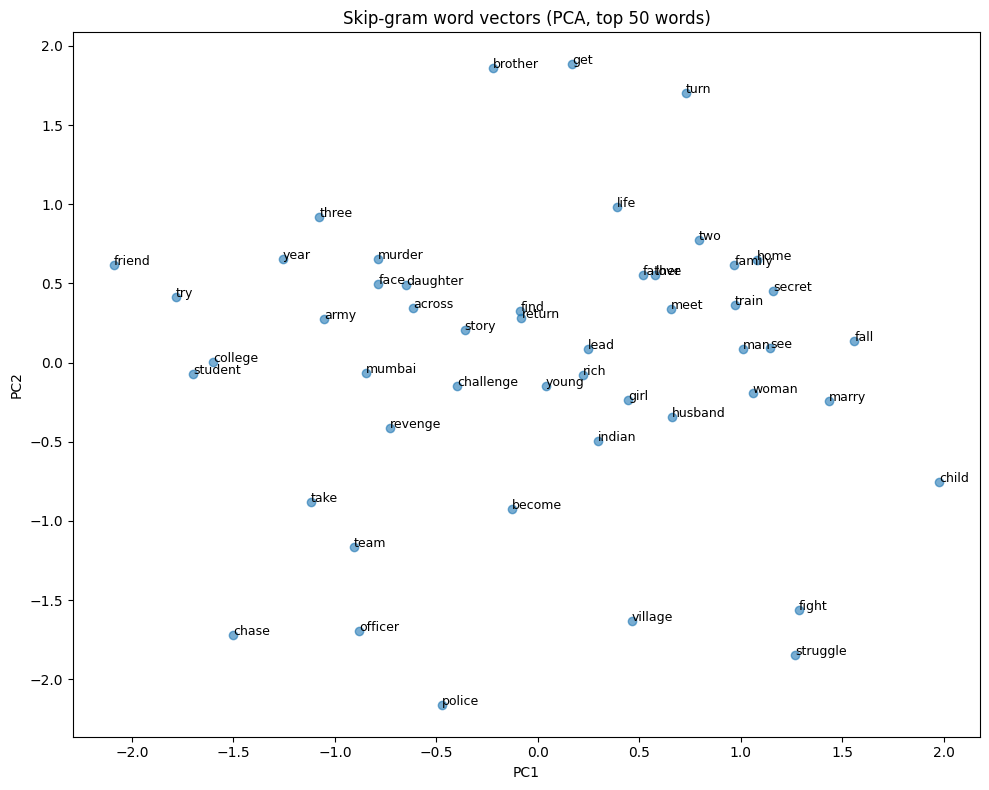

In [14]:
from sklearn.decomposition import PCA

top_n = min(50, len(wv))
words = wv.index_to_key[:top_n]
vecs = np.array([wv[w] for w in words])
pts = PCA(n_components=2, random_state=SEED).fit_transform(vecs)

plt.figure(figsize=(10, 8))
plt.scatter(pts[:, 0], pts[:, 1], alpha=0.6)
for (x, y), w in zip(pts, words):
    plt.annotate(w, (x, y), fontsize=9)
plt.title("Skip-gram word vectors (PCA, top %d words)" % top_n)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout(); plt.show()

**Observation (Section 8)**

- Do you see any clusters (e.g. family words together, crime words together)?
- PCA keeps only some of the variance. Why can two words look close in 2D but not be close in 100D?

*Your answer:*

## 9. Document vectors and similar movies

**Why:** Word2Vec gives vectors for **words**, but we often need one vector per **document**. The simplest method is to **average the word vectors** of all words in the document. Then we can find similar movies by cosine similarity.

**Pseudocode**
```
FUNCTION doc_vector(tokens):
    vectors = [ model[w] FOR w IN tokens IF w IN vocabulary ]
    IF vectors is empty: RETURN a vector of zeros
    RETURN average of vectors

doc_matrix = [ doc_vector(preprocess(description)) FOR each movie ]

FUNCTION similar_movies(title, k):
    RETURN the k movies whose doc_vector has the highest cosine similarity to the chosen movie
```

In [15]:
def doc_vector(tokens, model_wv):
    vecs = [model_wv[w] for w in tokens if w in model_wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(model_wv.vector_size)

df["tokens"] = df["description"].apply(preprocess)
doc_matrix = np.vstack([doc_vector(t, wv) for t in df["tokens"]])
print("Document matrix shape (movies x vector_size):", doc_matrix.shape)

Document matrix shape (movies x vector_size): (168, 100)


In [16]:
from sklearn.metrics.pairwise import cosine_similarity

def similar_movies(title, k=5):
    matches = df.index[df["movie"].str.lower() == title.lower()]
    if len(matches) == 0:
        return f"'{title}' not found"
    i = matches[0]
    sims = cosine_similarity(doc_matrix[i].reshape(1, -1), doc_matrix).ravel()
    order = sims.argsort()[::-1][1:k + 1]            # skip itself
    return pd.DataFrame({"movie": df["movie"].iloc[order].values,
                         "genre": df["genre"].iloc[order].values,
                         "cosine": sims[order].round(3)})

first_title = df["movie"].iloc[0]
print("Movie:", first_title, "|", df["genre"].iloc[0])
print(df["description"].iloc[0])
display(similar_movies(first_title))

Movie: Sholay | Action, Adventure
Two petty criminals are hired by a retired police officer to capture a ruthless dacoit terrorising a village. Friendship, revenge and iconic dialogue define this curry-western classic.


,movie,genre,cosine
0,Dhoom 2,"Action, Crime, Thriller",0.838
1,Singham,"Action, Crime",0.834
2,Kick,"Action, Comedy, Romance",0.829
3,Dhoom 3,"Action, Thriller, Crime",0.816
4,A Wednesday!,"Thriller, Crime",0.799


In [17]:
# Compare with TF-IDF based similarity for the same movie
from sklearn.feature_extraction.text import TfidfVectorizer
clean_text = df["tokens"].str.join(" ")
tfidf = TfidfVectorizer(token_pattern=r"\S+", lowercase=False)
X = tfidf.fit_transform(clean_text)
sims = cosine_similarity(X[0], X).ravel()
order = sims.argsort()[::-1][1:6]
print("TF-IDF neighbours of", first_title)
pd.DataFrame({"movie": df["movie"].iloc[order].values, "genre": df["genre"].iloc[order].values,
              "cosine": sims[order].round(3)})

TF-IDF neighbours of Sholay


,movie,genre,cosine
0,Article 15,"Crime, Drama, Thriller",0.134
1,Dhoom 3,"Action, Thriller, Crime",0.104
2,12th Fail,"Biography, Drama",0.098
3,Karan Arjun,"Action, Drama, Fantasy",0.095
4,Singham,"Action, Crime",0.092


**Observation (Section 9)**

- Are the similar movies sensible (same genre or theme)?
- How do Word2Vec-average neighbours differ from TF-IDF neighbours? (TF-IDF needs shared words, Word2Vec can match related words.)
- What does averaging lose (word order, word importance)? How could TF-IDF-weighted averaging help?

*Your answer:*

## 10. Effect of hyperparameters

**Pseudocode**
```
FOR each window IN [2, 5, 10]:
    train Skip-gram with that window
    RECORD the top neighbours of the same word and the similarity of the same pair
COMPARE
```
Small `window` captures **syntactic / tight** relations, large `window` captures **topical** relations.

In [18]:
probe = wv.index_to_key[0]
pair = (wv.index_to_key[0], wv.index_to_key[1])
rows = []
for window in [2, 5, 10]:
    for vs in [50, 100]:
        m = Word2Vec(sentences, sg=1, vector_size=vs, window=window, min_count=1,
                     epochs=100, negative=5, workers=1, seed=SEED)
        rows.append({
            "window": window, "vector_size": vs,
            f"top-3 neighbours of {probe!r}": [w for w, _ in m.wv.most_similar(probe, topn=3)],
            f"similarity{pair}": round(float(m.wv.similarity(*pair)), 3),
        })
pd.DataFrame(rows)

,window,vector_size,top-3 neighbours of 'love',"similarity('love', 'man')"
0,2,50,"[fall, explore, hide]",0.629
1,2,100,"[fall, pakistani, mysterious]",0.778
2,5,50,"[away, run, prince]",0.380
3,5,100,"[run, salim, prince]",0.420
4,10,50,"[romance, away, decade]",0.308
5,10,100,"[run, away, romance]",0.310


**Observation (Section 10)**

- How do the neighbours change when the window grows?
- Does a bigger `vector_size` help on such a small corpus?

*Your answer:*

## 11. Optional: compare with pretrained vectors

Our model learned from ~2,000 words. **Pretrained** vectors were trained on billions of words, so analogies and similarities become meaningful. This cell downloads small GloVe vectors (about 66 MB) and needs internet. If it fails, the notebook simply skips it.

In [19]:
try:
    import io, contextlib
    import gensim.downloader as api
    with contextlib.redirect_stdout(io.StringIO()):   # hide the download progress bar
        glove = api.load("glove-wiki-gigaword-50")    # 400k words, 50 dimensions
    print("Pretrained model loaded. Vocabulary:", len(glove))
    print("\nking - man + woman:")
    print(glove.most_similar(positive=["king", "woman"], negative=["man"], topn=3))
    print("\nMost similar to 'love':")
    print(glove.most_similar("love", topn=5))
except Exception as e:
    print("Skipped pretrained comparison:", type(e).__name__, "-", e)

Pretrained model loaded. Vocabulary: 400000

king - man + woman:
[('queen', 0.8523604273796082), ('throne', 0.7664334177970886), ('prince', 0.7592144012451172)]

Most similar to 'love':
[('dream', 0.8429608941078186), ('life', 0.8403438925743103), ('dreams', 0.8398564457893372), ('loves', 0.8361135125160217), ('me', 0.8351817727088928)]


**Observation (Section 11)**

- How do the pretrained results compare with the ones trained on the Bollywood dataset?
- When should you train your own Word2Vec, and when should you use pretrained vectors?

*Your answer:*

## Overall observations for the assignment

- Word2Vec gives **dense, low-dimensional** vectors, unlike one hot / bag of words / TF-IDF, which are sparse and as long as the vocabulary.
- It captures **similarity of context**, so related words have close vectors, something Bag of Words and TF-IDF cannot do.
- It needs a **lot of data**. With 168 short descriptions the neighbours are noisy.
- **CBOW** is faster, **Skip-gram** is better for small data and rare words.
- It gives **one vector per word** (no context-dependent meaning, no OOV handling). Later models (FastText, BERT) fix these limits.

## Summary of representations

| Representation | Vector length | Sparse or dense | Captures meaning similarity |
|---|---|---|---|
| One hot | vocabulary size | sparse | No |
| Bag of Words / TF-IDF | vocabulary size | sparse | No |
| Word2Vec | 50 to 300 (you choose) | dense | Yes |

## Next steps
Use the document vectors from Section 9 as features for a **genre classifier**, or train **FastText** (`gensim.models.FastText`) to handle words it has not seen.